In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import tensorflow as tf
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import TargetEncoder, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from keras import Sequential
from keras.layers import Dense, Input, Normalization
from keras.optimizers import Adam
from keras.losses import MeanSquaredError

I0000 00:00:1793007051.848555   14956 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
dataset = pd.read_csv('../data/life_expectancy/Life Expectancy Data.csv')
dataset.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

array([[<Axes: title={'center': 'Year'}>,
        <Axes: title={'center': 'Life expectancy '}>,
        <Axes: title={'center': 'Adult Mortality'}>,
        <Axes: title={'center': 'infant deaths'}>],
       [<Axes: title={'center': 'Alcohol'}>,
        <Axes: title={'center': 'percentage expenditure'}>,
        <Axes: title={'center': 'Hepatitis B'}>,
        <Axes: title={'center': 'Measles '}>],
       [<Axes: title={'center': ' BMI '}>,
        <Axes: title={'center': 'under-five deaths '}>,
        <Axes: title={'center': 'Polio'}>,
        <Axes: title={'center': 'Total expenditure'}>],
       [<Axes: title={'center': 'Diphtheria '}>,
        <Axes: title={'center': ' HIV/AIDS'}>,
        <Axes: title={'center': 'GDP'}>,
        <Axes: title={'center': 'Population'}>],
       [<Axes: title={'center': ' thinness  1-19 years'}>,
        <Axes: title={'center': ' thinness 5-9 years'}>,
        <Axes: title={'center': 'Income composition of resources'}>,
        <Axes: title={'center

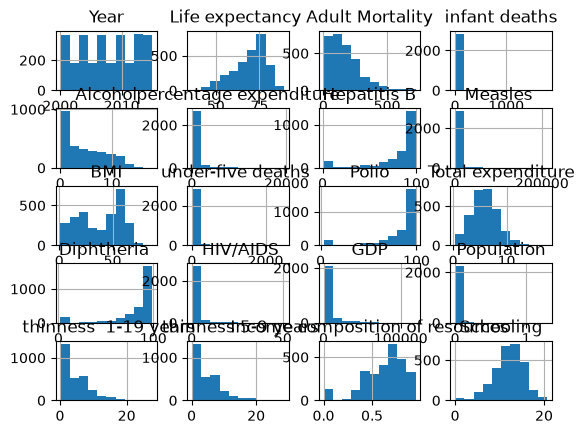

In [4]:
# Exploratory Data Analysis (EDA)

# Distributions via histograms

dataset.hist()

In [5]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

Status
Developing    2426
Developed      512
Name: count, dtype: int64


<Axes: xlabel='Status'>

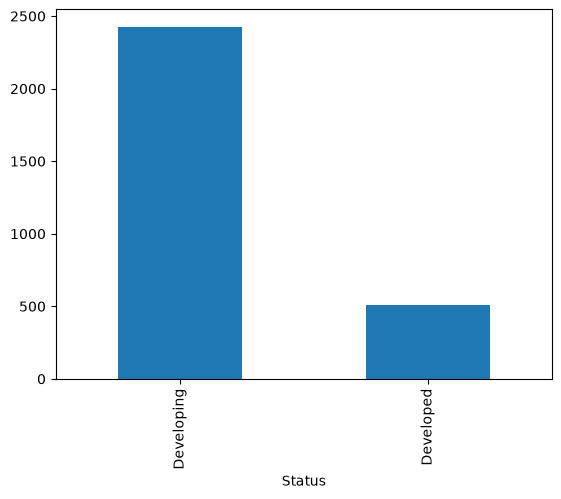

In [6]:
# Distributions of categorical data can be analyzed by looking at the value counts

print(dataset['Status'].value_counts())
dataset['Status'].value_counts().plot.bar()


In [7]:
# Correlation analysis 
 
# Perform correlation analysis only on the numerical columns 
correlation = dataset.drop(['Country', 'Status'], axis=1).corr()
correlation.style.background_gradient(cmap='coolwarm')

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
Year,1.000000,0.170033,-0.079052,-0.037415,-0.052990,0.031400,0.104333,-0.082493,0.108974,-0.042937,0.094158,0.090740,0.134337,-0.139741,0.101620,0.016969,-0.047876,-0.050929,0.243468,0.209400
Life expectancy,0.170033,1.000000,-0.696359,-0.196557,0.404877,0.381864,0.256762,-0.157586,0.567694,-0.222529,0.465556,0.218086,0.479495,-0.556556,0.461455,-0.021538,-0.477183,-0.471584,0.724776,0.751975
Adult Mortality,-0.079052,-0.696359,1.000000,0.078756,-0.195848,-0.242860,-0.162476,0.031176,-0.387017,0.094146,-0.274823,-0.115281,-0.275131,0.523821,-0.296049,-0.013647,0.302904,0.308457,-0.457626,-0.454612
infant deaths,-0.037415,-0.196557,0.078756,1.000000,-0.115638,-0.085612,-0.223566,0.501128,-0.227279,0.996629,-0.170689,-0.128616,-0.175171,0.025231,-0.108427,0.556801,0.465711,0.471350,-0.145139,-0.193720
Alcohol,-0.052990,0.404877,-0.195848,-0.115638,1.000000,0.341285,0.087549,-0.051827,0.330408,-0.112370,0.221734,0.296942,0.222020,-0.048845,0.354712,-0.035252,-0.428795,-0.417414,0.450040,0.547378
percentage expenditure,0.031400,0.381864,-0.242860,-0.085612,0.341285,1.000000,0.016274,-0.056596,0.228700,-0.087852,0.147259,0.174420,0.143624,-0.097857,0.899373,-0.025662,-0.251369,-0.252905,0.381952,0.389687
Hepatitis B,0.104333,0.256762,-0.162476,-0.223566,0.087549,0.016274,1.000000,-0.120529,0.150380,-0.233126,0.486171,0.058280,0.611495,-0.112675,0.083903,-0.123321,-0.120429,-0.124960,0.199549,0.231117
Measles,-0.082493,-0.157586,0.031176,0.501128,-0.051827,-0.056596,-0.120529,1.000000,-0.175977,0.507809,-0.136166,-0.106241,-0.141882,0.030899,-0.076466,0.265966,0.224808,0.221072,-0.129568,-0.137225
BMI,0.108974,0.567694,-0.387017,-0.227279,0.330408,0.228700,0.150380,-0.175977,1.000000,-0.237669,0.284569,0.242503,0.283147,-0.243717,0.301557,-0.072301,-0.532025,-0.538911,0.508774,0.546961
under-five deaths,-0.042937,-0.222529,0.094146,0.996629,-0.112370,-0.087852,-0.233126,0.507809,-0.237669,1.000000,-0.188720,-0.130148,-0.195668,0.038062,-0.112081,0.544423,0.467789,0.472263,-0.163305,-0.209373


In [8]:
# Processing

# Remove missing values
dataset.dropna(inplace=True)

# Alternatively, we could imput replacement data
# dataset.fillna(dataset.mean(), inplace=True)

# Encoding
# Manual encoding using pandas
dataset['Status'] = dataset['Status'].replace({'Developing':0, 'Developed':1}).astype('int')


# dataset.dropna(subset='Life expectancy ', inplace=True)
# Data leakage. Should be fitted on training data only. This follows below the splitting of the data
# dataset['Country'] = TargetEncoder().fit_transform(dataset[['Country']], dataset['Life expectancy '])

# Alternatively use one hot encoding which isn't capable of causing data leaks

In [9]:
# We want to perform mean normalization. This should be done on the numerical features only, so
# it is helpful to have a list of all the numerical features
numerical_features = dataset.drop(['Country', 'Status', 'Life expectancy '], axis=1).columns
numerical_features

# Performing normalization on the entire dataset will cause data leakage
# Should instead be done on training data only, and reused for validation and testing
# Mean normalization
# dataset[numerical_features] = (dataset[numerical_features] - dataset[numerical_features].mean())/dataset[numerical_features].std()
# Using sklearn
# dataset[numerical_features] = Normalizer().fit_transform(dataset[numerical_features])

Index(['Year', 'Adult Mortality', 'infant deaths', 'Alcohol',
       'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ',
       'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ',
       ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years',
       ' thinness 5-9 years', 'Income composition of resources', 'Schooling'],
      dtype='str')

In [10]:
# Split our data into TrainValidation and Testing
dataset_trainval, dataset_test = train_test_split(dataset, test_size=0.4, shuffle=True)
features_trainval = dataset_trainval.drop('Life expectancy ', axis=1)
features_test = dataset_test.drop('Life expectancy ', axis=1)
targets_trainval = dataset_trainval['Life expectancy ']
targets_test = dataset_test['Life expectancy ']
# Print the shapes of the splits to ensure 60/40 split
print(features_trainval.shape)
print(features_test.shape)



(989, 21)
(660, 21)


In [11]:
# Perform target encoding on the training and validation data. This will cause a leak between the training and validation
# folds i.e. it can make the hyperparameter tuning produce results that are over optimistic, but after tuning with 
# GridSearchCV, the estimators are refitted on the entire trainval split i.e. there's no leakage to the final test split
# Fit on trainval data
country_encoder = TargetEncoder().fit(features_trainval[['Country']], targets_trainval)
features_trainval_encoded = features_trainval.copy()
features_test_encoded = features_test.copy()
# Transform the splits using the trained target encoder
features_trainval_encoded['Country'] = country_encoder.transform(features_trainval[['Country']])
features_test_encoded['Country'] = country_encoder.transform(features_test[['Country']])

numerical_features_ = numerical_features.append(pd.Index(['Country']))

In [12]:
# Create a function that test the performance on the test split
def test(model):
    predictions = model.predict(features_test_encoded)
    print(f'MSE: {mean_squared_error(targets_test, predictions)}')
    print(f'MAE: {mean_absolute_error(targets_test, predictions)}')
    print(f'R2: {r2_score(targets_test, predictions)}')


In [13]:
# Create and tune a DT

# Create a dictionary that specifies which parameters to tune and which values
# to try for each of the parameters
dt_params = {
    'max_depth': [2, 4, 8, 12],
    'max_features': [None, 'sqrt', 4, 6]
}

# Create a GridSearchCV object that wraps around the DT and pass in our parameter dictionary
dt_grid = GridSearchCV(DecisionTreeRegressor(), dt_params)
# Peform automated tuning by fitting the gridsearch object to the data. After tuning, the
# estimator is by default fitted to the entire dataset (trainval) with the best parameter values
dt_grid.fit(features_trainval_encoded, targets_trainval)
# Test performance
test(dt_grid)


MSE: 5.964685279557101
MAE: 1.6572927493960765
R2: 0.9243366390492137


In [14]:
# Store the results of the tuning in a dataframe for easy access and analysis
dt_cv_results = pd.DataFrame(dt_grid.cv_results_)
dt_cv_results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,param_max_features,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.003372,0.000668,0.001326,0.000072,2,None,"{'max_depth': 2, 'max_features': None}",0.887466,0.863778,0.866324,0.866342,0.844539,0.865690,0.013609,10
1,0.001828,0.000018,0.001265,0.000035,2,sqrt,"{'max_depth': 2, 'max_features': 'sqrt'}",0.615178,0.677529,0.609472,0.758931,0.723362,0.676894,0.058727,16
2,0.001725,0.000044,0.001206,0.000034,2,4,"{'max_depth': 2, 'max_features': 4}",0.617877,0.702869,0.855130,0.760828,0.474146,0.682170,0.129567,15
3,0.001823,0.000043,0.001174,0.000024,2,6,"{'max_depth': 2, 'max_features': 6}",0.811327,0.790147,0.756576,0.678236,0.667180,0.740693,0.058296,14
4,0.004047,0.000033,0.001193,0.000042,4,None,"{'max_depth': 4, 'max_features': None}",0.941289,0.932481,0.941612,0.929459,0.922272,0.933423,0.007347,1
5,0.001962,0.000076,0.001176,0.000040,4,sqrt,"{'max_depth': 4, 'max_features': 'sqrt'}",0.703655,0.822173,0.821440,0.832966,0.825093,0.801065,0.048876,12
6,0.001943,0.000041,0.001168,0.000027,4,4,"{'max_depth': 4, 'max_features': 4}",0.854973,0.820026,0.742776,0.732180,0.671223,0.764236,0.065552,13
7,0.002218,0.000080,0.001192,0.000039,4,6,"{'max_depth': 4, 'max_features': 6}",0.826081,0.932093,0.852880,0.861278,0.775668,0.849600,0.050934,11
8,0.006309,0.000078,0.001345,0.000203,8,None,"{'max_depth': 8, 'max_features': None}",0.922862,0.946230,0.938333,0.924241,0.915304,0.929394,0.011235,2
9,0.002501,0.000053,0.001201,0.000028,8,sqrt,"{'max_depth': 8, 'max_features': 'sqrt'}",0.868052,0.909184,0.893594,0.806304,0.880290,0.871485,0.035349,9


<Axes: xlabel='param_max_features', ylabel='mean_test_score'>

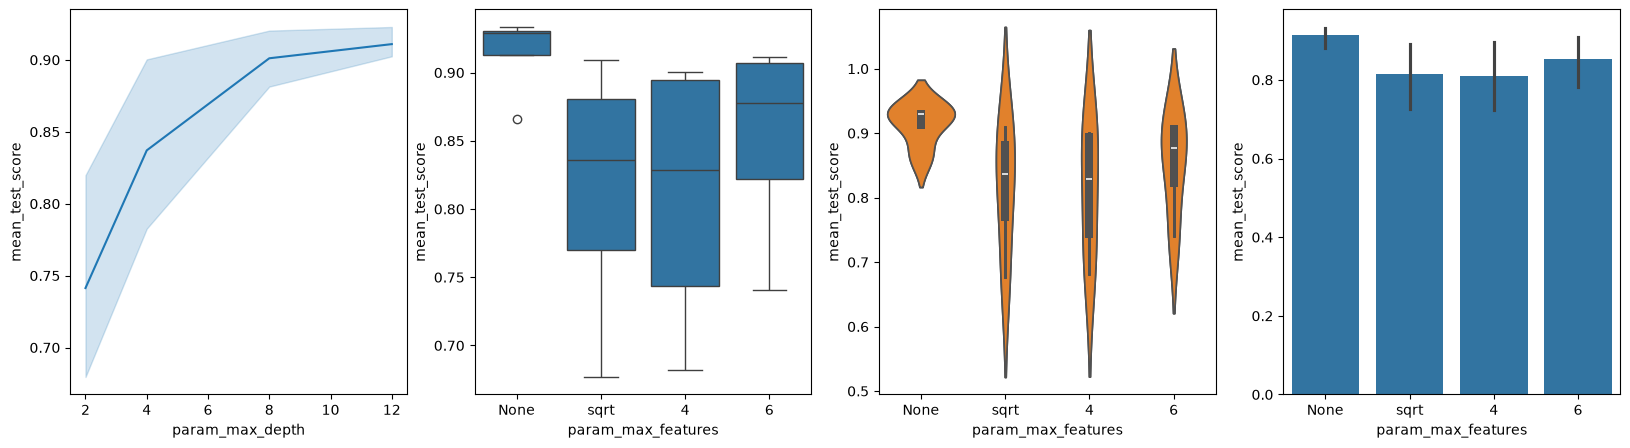

In [15]:
# We can use plots to determine that our parameter choices cover the appropriate values
# We need to make sure that we have tested values that allow for the best possible performance
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
# With all numeric alternatives we can simply plot a line and look for the peak
sb.lineplot(data=dt_cv_results, x='param_max_depth', y='mean_test_score', ax=axs[0])
# With values covering strings and None we need to deal with the None values and use a different plot type
dt_cv_results_ = pd.DataFrame(dt_grid.cv_results_)
dt_cv_results_['param_max_features'] = dt_cv_results_['param_max_features'].fillna('None')
sb.boxplot(data=dt_cv_results_, x='param_max_features', y='mean_test_score', ax=axs[1])
sb.violinplot(data=dt_cv_results_, x='param_max_features', y='mean_test_score', ax=axs[2])
sb.violinplot(data=dt_cv_results_, x='param_max_features', y='mean_test_score', ax=axs[2])
sb.barplot(data=dt_cv_results_, x='param_max_features', y='mean_test_score', ax=axs[3])

In [16]:
# Train a RandomForest regressor

# The hyperparameter grid to test for our random forest model
rf_params = {
    'n_estimators': [100, 300], 
    'max_depth': [None, 3, 10, 16]
}
# Create the gridsearch object that wraps around the estimator. This time we specify
# to use 18 threads to speed up the tuning
rf_grid = GridSearchCV(RandomForestRegressor(), rf_params, n_jobs=18)
# Perform the tuning and fit the estimator to the best combination
rf_grid.fit(features_trainval_encoded, targets_trainval)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 3, ...], 'n_estimators': [100, 300]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",18
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information printed

In [17]:
# Test the performance of the best random forest regressor found
test(rf_grid)

MSE: 3.4345999762626302
MAE: 1.0679823232323225
R2: 0.9564313345054112


<Axes: xlabel='param_max_depth', ylabel='mean_test_score'>

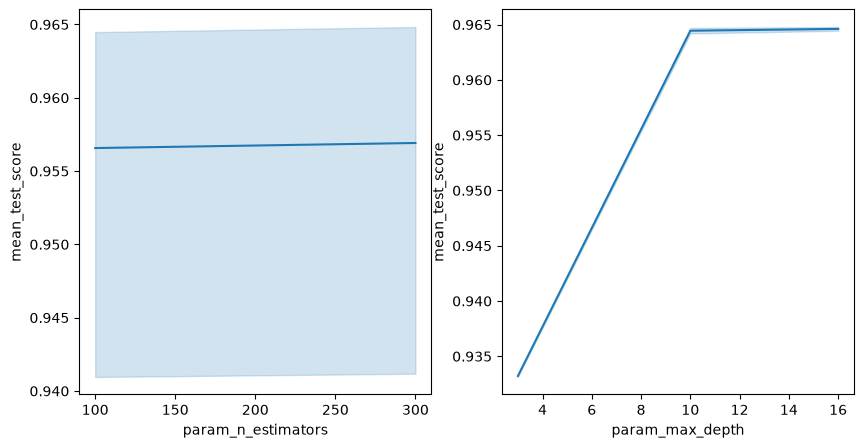

In [18]:
# Analyze our parameter grid to ensure we've included appropriate values
rf_cv_results = pd.DataFrame(rf_grid.cv_results_)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
sb.lineplot(data=rf_cv_results, x='param_n_estimators', y='mean_test_score', ax=axs[0])
sb.lineplot(data=rf_cv_results, x='param_max_depth', y='mean_test_score', ax=axs[1])

In [19]:
# Pipelines

# Ensure that the dataset has the unencoded Country feature
dataset.info()

<class 'pandas.DataFrame'>
Index: 1649 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          1649 non-null   str    
 1   Year                             1649 non-null   int64  
 2   Status                           1649 non-null   int64  
 3   Life expectancy                  1649 non-null   float64
 4   Adult Mortality                  1649 non-null   float64
 5   infant deaths                    1649 non-null   int64  
 6   Alcohol                          1649 non-null   float64
 7   percentage expenditure           1649 non-null   float64
 8   Hepatitis B                      1649 non-null   float64
 9   Measles                          1649 non-null   int64  
 10   BMI                             1649 non-null   float64
 11  under-five deaths                1649 non-null   int64  
 12  Polio                            164

In [20]:
# We store the unique values of Country in a list for future use in encoders
countries = list(dataset['Country'].unique())

In [21]:
# Create a pipeline that has a ColumnTransformer before the estimator. We specify the 
# names and types of each step in the pipeline
dt_pipe = Pipeline([
    ('encode', ColumnTransformer([('country', TargetEncoder(), ['Country']), ('numerical', 'passthrough', numerical_features)])), 
    ('estimator', DecisionTreeRegressor())
])
dt_pipe.get_params()

{'memory': None,
 'steps': [('encode',
   ColumnTransformer(transformers=[('country', TargetEncoder(), ['Country']),
                                   ('numerical', 'passthrough',
                                    Index(['Year', 'Adult Mortality', 'infant deaths', 'Alcohol',
          'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ',
          'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ',
          ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years',
          ' thinness 5-9 years', 'Income composition of resources', 'Schooling'],
         dtype='str'))])),
  ('estimator', DecisionTreeRegressor())],
 'transform_input': None,
 'verbose': False,
 'encode': ColumnTransformer(transformers=[('country', TargetEncoder(), ['Country']),
                                 ('numerical', 'passthrough',
                                  Index(['Year', 'Adult Mortality', 'infant deaths', 'Alcohol',
        'percentage expenditure', 'Hepatitis B', 'Measles ', '

In [22]:
# Investigate the number of each country. See below for reason why
features_trainval['Country'].value_counts()

Country
Brazil           12
Vanuatu          12
Lebanon          12
Latvia           12
Maldives         11
                 ..
Guinea            3
Netherlands       3
Guinea-Bissau     2
Haiti             1
Ireland           1
Name: count, Length: 132, dtype: int64

In [23]:

dt_pipe_params = {
    'estimator__max_depth': [2, 8, 16], 
    # This can cause issues (depending on the random seed) due to the sparsity of the country 
    # feature (see above) i.e. we have validations folds that contain values that are not present in the training fold
    # 'encode__country': [TargetEncoder(), OneHotEncoder()]
    'encode__country': [TargetEncoder(categories=[countries]), OneHotEncoder(categories=[countries])],
    'encode__numerical': ['passthrough', StandardScaler(), MinMaxScaler()]
}
dt_pipe_grid = GridSearchCV(dt_pipe, dt_pipe_params)
dt_pipe_grid.fit(features_trainval, targets_trainval)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'encode__country': [TargetEncoder...ombia', ...]]), OneHotEncoder...ombia', ...]])], 'encode__numerical': ['passthrough', StandardScaler(), ...], 'estimator__max_depth': [2, 8, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` de

In [24]:
pd.DataFrame(dt_pipe_grid.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_encode__country,param_encode__numerical,param_estimator__max_depth,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.008893,0.000779,0.003115,0.000158,"TargetEncoder(categories=[['Afghanistan', 'Alb...",passthrough,2,{'encode__country': TargetEncoder(categories=[...,0.884106,0.858212,0.875805,0.814787,0.819837,0.850549,0.028442,14
1,0.011783,0.000197,0.002862,0.000085,"TargetEncoder(categories=[['Afghanistan', 'Alb...",passthrough,8,{'encode__country': TargetEncoder(categories=[...,0.875089,0.926617,0.945149,0.922556,0.906986,0.915279,0.023485,5
2,0.014164,0.000349,0.003021,0.000133,"TargetEncoder(categories=[['Afghanistan', 'Alb...",passthrough,16,{'encode__country': TargetEncoder(categories=[...,0.927020,0.924730,0.941698,0.914828,0.911469,0.923949,0.010621,2
3,0.009248,0.000212,0.003428,0.000045,"TargetEncoder(categories=[['Afghanistan', 'Alb...",StandardScaler(),2,{'encode__country': TargetEncoder(categories=[...,0.876666,0.831229,0.868917,0.813689,0.848237,0.847748,0.023313,15
4,0.013145,0.000530,0.004725,0.002453,"TargetEncoder(categories=[['Afghanistan', 'Alb...",StandardScaler(),8,{'encode__country': TargetEncoder(categories=[...,0.914337,0.923748,0.926835,0.871428,0.926135,0.912497,0.021015,6
5,0.014967,0.000150,0.003513,0.000048,"TargetEncoder(categories=[['Afghanistan', 'Alb...",StandardScaler(),16,{'encode__country': TargetEncoder(categories=[...,0.892931,0.921608,0.925479,0.917116,0.921681,0.915763,0.011719,4
6,0.009403,0.000702,0.003456,0.000108,"TargetEncoder(categories=[['Afghanistan', 'Alb...",MinMaxScaler(),2,{'encode__country': TargetEncoder(categories=[...,0.872704,0.882385,0.866249,0.827194,0.821491,0.854005,0.024823,13
7,0.012531,0.000133,0.003342,0.000022,"TargetEncoder(categories=[['Afghanistan', 'Alb...",MinMaxScaler(),8,{'encode__country': TargetEncoder(categories=[...,0.921891,0.925237,0.936237,0.904775,0.918928,0.921414,0.010174,3
8,0.014727,0.000174,0.003405,0.000066,"TargetEncoder(categories=[['Afghanistan', 'Alb...",MinMaxScaler(),16,{'encode__country': TargetEncoder(categories=[...,0.931207,0.938591,0.933766,0.937120,0.922853,0.932707,0.005560,1
9,0.011644,0.006852,0.003907,0.000127,"OneHotEncoder(categories=[['Afghanistan', 'Alb...",passthrough,2,{'encode__country': OneHotEncoder(categories=[...,0.677286,0.723623,0.700115,0.652181,0.710967,0.692834,0.025394,16


In [25]:
# We create a new test function for testing pipelines. The difference is that 
# this uses the unencoded test data
def test_pipe(pipe):
    predictions = pipe.predict(features_test)
    print(f'MSE: {mean_squared_error(targets_test, predictions)}')
    print(f'MAE: {mean_absolute_error(targets_test, predictions)}')
    print(f'R2: {r2_score(targets_test, predictions)}')

In [26]:
test_pipe(dt_pipe_grid)

MSE: 4.847472980957534
MAE: 1.3112821067821065
R2: 0.9385087258309447


In [27]:
# Train a simple neural network (MLPRegressor)

# Our hyperparameter grid. See the documentaion for details
nn_params = {
    # 'solver': ['adam', 'lbfgs'],
    'hidden_layer_sizes': [(20,), (20, 10), (20, 15, 10, 5)]
}

# Tune and fit to unencoded data
# This causes issues. Most likely due to not having scaled the numerical features
nn_grid = GridSearchCV(MLPRegressor(max_iter=500), nn_params)
nn_grid.fit(features_trainval_encoded, targets_trainval)
test(nn_grid)

/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MSE: 5716537.161896443
MAE: 1047.4541356805125
R2: -72514.54682215708
